Sveučilište u Zagrebu  
Fakultet elektrotehnike i računarstva  
  
## Strojno učenje 1 2026./2027.  
http://www.fer.unizg.hr/predmet/struce1

------------------------------

### Prva laboratorijska vježba: Linearna regresija

*Verzija: 1.0
Zadnji put ažurirano: 1. 10. 2021.*

(c) 2015-2026 Jan Šnajder, Domagoj Alagić 

------------------------------

### Pravila predaje
Predajom vježbe potvrđujete sljedeće točke:
1. Niste od drugoga primili pomoć pri rješavanju vježbe;
2. Atribuirali ste dijelove koda koji su preuzeti s interneta referencirajući ih u komentarima;
3. Niste koristili dijelove koda s interneta koji su specifični za laboratorijsku vježbu;
4. Niste koristili UI-asistente za kodiranje kao npr. GitHub Copilot (uključivo alate generativne UI, kao što je ChatGPT).

**Povreda bilo kojeg od gornjih pravila smatra se prekršajem te povlači akademske sankcije.**

### Upute

Prva laboratorijska vježba sastoji se od sedam zadataka. U nastavku slijedite upute navedene u ćelijama s tekstom. Rješavanje vježbe svodi se na **dopunjavanje ove bilježnice**: umetanja ćelije ili više njih **ispod** teksta zadatka, pisanja odgovarajućeg kôda te evaluiranja ćelija. 

Osigurajte da u potpunosti **razumijete** kôd koji ste napisali. Kod predaje vježbe, morate biti u stanju na zahtjev asistenta (ili demonstratora) preinačiti i ponovno evaluirati Vaš kôd. Nadalje, morate razumjeti teorijske osnove onoga što radite, u okvirima onoga što smo obradili na predavanju. Ispod nekih zadataka možete naći i pitanja koja služe kao smjernice za bolje razumijevanje gradiva (**nemojte pisati** odgovore na pitanja u bilježnicu). Stoga se nemojte ograničiti samo na to da riješite zadatak, nego slobodno eksperimentirajte. To upravo i jest svrha ovih vježbi.

Vježbe trebate raditi **samostalno**. Možete se konzultirati s drugima o načelnom načinu rješavanja, ali u konačnici morate sami odraditi vježbu. U protivnome vježba nema smisla.

In [1]:
# Učitaj osnovne biblioteke...
import numpy as np
import sklearn
import matplotlib.pyplot as plt
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


### 1. Jednostavna regresija

Zadan je skup primjera $\mathcal{D}=\{(x^{(i)},y^{(i)})\}_{i=1}^4 = \{(0,4),(1,1),(2,2),(4,5)\}$. Primjere predstavite matricom $\mathbf{X}$ dimenzija $N\times n$ (u ovom slučaju $4\times 1$) i vektorom oznaka $\textbf{y}$, dimenzija $N\times 1$ (u ovom slučaju $4\times 1$), na sljedeći način:


In [2]:
X = np.array([[0],[1],[2],[4]])
y = np.array([4,1,2,5])

### (a)

Proučite funkciju [`PolynomialFeatures`](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html) iz biblioteke `sklearn` i upotrijebite je za generiranje matrice dizajna $\mathbf{\Phi}$ koja ne koristi preslikavanje u prostor više dimenzije (samo će svakom primjeru biti dodane *dummy* jedinice; $m=n+1$).


In [3]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=1, include_bias=True)
matrix = poly.fit_transform(X)
print(matrix)

[[1. 0.]
 [1. 1.]
 [1. 2.]
 [1. 4.]]


### (b)

Upoznajte se s modulom [`linalg`](http://docs.scipy.org/doc/numpy/reference/routines.linalg.html). Izračunajte težine $\mathbf{w}$ modela linearne regresije kao $\mathbf{w}=(\mathbf{\Phi}^\intercal\mathbf{\Phi})^{-1}\mathbf{\Phi}^\intercal\mathbf{y}$. Zatim se uvjerite da isti rezultat možete dobiti izračunom pseudoinverza $\mathbf{\Phi}^+$ matrice dizajna, tj. $\mathbf{w}=\mathbf{\Phi}^+\mathbf{y}$, korištenjem funkcije [`pinv`](http://docs.scipy.org/doc/numpy/reference/generated/numpy.linalg.pinv.html).

In [4]:
from numpy import linalg
weights = np.matmul(
        np.matmul(
            linalg.inv(
                np.matmul(
                    np.transpose(matrix),
                    matrix
                )
            ), 
            np.transpose(matrix)
        ),
    y
)
weights_pinv = np.matmul(linalg.pinv(matrix), y)
print("weigths: ", weights)
print("weigths_pinv: ", weights_pinv)


weigths:  [2.2        0.45714286]
weigths_pinv:  [2.2        0.45714286]


Radi jasnoće, u nastavku je vektor $\mathbf{x}$ s dodanom *dummy* jedinicom $x_0=1$ označen kao $\tilde{\mathbf{x}}$.

### (c)

Prikažite primjere iz $\mathcal{D}$ i funkciju $h(\tilde{\mathbf{x}})=\mathbf{w}^\intercal\tilde{\mathbf{x}}$. Izračunajte pogrešku učenja prema izrazu $E(h|\mathcal{D})=\frac{1}{2}\sum_{i=1}^N(\tilde{\mathbf{y}}^{(i)} - h(\tilde{\mathbf{x}}^{(i)}))^2$. Možete koristiti funkciju srednje kvadratne pogreške [`mean_squared_error`]( http://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html) iz modula [`sklearn.metrics`](http://scikit-learn.org/stable/modules/classes.html#module-sklearn.metrics).

**Q:** Gore definirana funkcija pogreške $E(h|\mathcal{D})$ i funkcija srednje kvadratne pogreške nisu posve identične. U čemu je razlika? Koja je "realnija"?

In [5]:
from sklearn.metrics import mean_squared_error
# predictions = np.matmul(np.transpose(weights), matrix)
predictions = np.matmul(matrix, weights)
mse = mean_squared_error(y, predictions)
ehd = 0.5 * np.sum((y - predictions) ** 2)
print(mse)
print(ehd)

2.0428571428571427
4.085714285714285


### (d)

Uvjerite se da za primjere iz $\mathcal{D}$ težine $\mathbf{w}$ ne možemo naći rješavanjem sustava $\mathbf{w}=\mathbf{\Phi}^{-1}\mathbf{y}$, već da nam doista treba pseudoinverz.

**Q:** Zašto je to slučaj? Bi li se problem mogao riješiti preslikavanjem primjera u višu dimenziju? Ako da, bi li to uvijek funkcioniralo, neovisno o skupu primjera $\mathcal{D}$? Pokažite na primjeru.

In [6]:
try:
    new_weights = np.matmul(linalg.inv(matrix), y)
    print(new_weights)
except Exception as e:
    print(e)
# Baca error jer matrica nije kvadratna
# Ako preslikavanjem u visu dimenziju dobijemo kvadratnu bismo mogli raditi inverz
# ne bi uvijek funkcioniralo jer bi dobili pododredeni sustav jer bi imali vise znacajki od primjera

Last 2 dimensions of the array must be square


### (e) 

Proučite klasu [`LinearRegression`](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) iz modula [`sklearn.linear_model`](http://scikit-learn.org/stable/modules/classes.html#module-sklearn.linear_model). Provjerite jesu li težine koje izračunava ta funkcija (dostupne pomoću atributa `coef_` i `intercept_`) jednake onima koje ste izračunali gore. Ako nisu, prilagodite kôd tako da jest.

**NB:** Obratite pozornost na to kako klase [`LinearRegression`](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) i [`PolynomialFeatures`](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html) koriste pomak i osigurajte da ga ne dodajete više puta.

Izračunajte predikcije modela (metoda `predict`) i uvjerite se da je pogreška učenja identična onoj koju ste ranije izračunali.

In [7]:
from sklearn.linear_model import LinearRegression
model = LinearRegression(fit_intercept=False)
model.fit(matrix, y)
print("tezine =", model.coef_)
y_pred = model.predict(matrix)
err = 0.5 * np.sum((y - y_pred)**2)
print("err =", err)

tezine = [2.2        0.45714286]
err = 4.085714285714286


### 2. Polinomijalna regresija i utjecaj šuma

### (a)

Razmotrimo sada regresiju na većem broju primjera. Definirajte funkciju `make_labels(X, f, noise=0)` koja uzima matricu neoznačenih primjera $\mathbf{X}_{N\times n}$ te generira vektor njihovih oznaka $\mathbf{y}_{N\times 1}$. Oznake se generiraju kao $y^{(i)} = f(x^{(i)})+\mathcal{N}(0,\sigma^2)$, gdje je $f:\mathbb{R}^n\to\mathbb{R}$ stvarna funkcija koja je generirala podatke (koja nam je u stvarnosti nepoznata), a $\sigma$ je standardna devijacija Gaussovog šuma, definirana parametrom `noise`. Za generiranje šuma možete koristiti funkciju [`numpy.random.normal`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html). 

Generirajte skup za učenje od $N=50$ primjera uniformno distribuiranih u intervalu $[-5,5]$ pomoću funkcije $f(x) = 5 + x -2 x^2 -5 x^3$ uz šum  $\sigma=200$:

In [8]:
from numpy.random import normal
def make_labels(X, f, noise=0):
    y = np.array([f(xi) for xi in X])
    if noise > 0:
        y += normal(0, noise, size=X.shape)
    return y


In [9]:
def make_instances(x1, x2, N) :
    return np.array([np.array([x]) for x in np.linspace(x1,x2,N)])

In [10]:
from numpy.random import normal
def make_labels(X, f, noise=0):
    y = np.array([f(xi) for xi in X])
    if noise > 0:
        y += normal(0, noise, size=X.shape)
    return y

def f(x):
    return 5 + x - 2 * x**2 - 5 * x**3

X = make_instances(-5, 5, 50)
y = make_labels(X, f, noise=200)
# print("X =", X[:5])
# print("y =", y[:5])

Prikažite taj skup funkcijom [`scatter`](http://matplotlib.org/api/pyplot_api.html#matplotlib.pyplot.scatter).

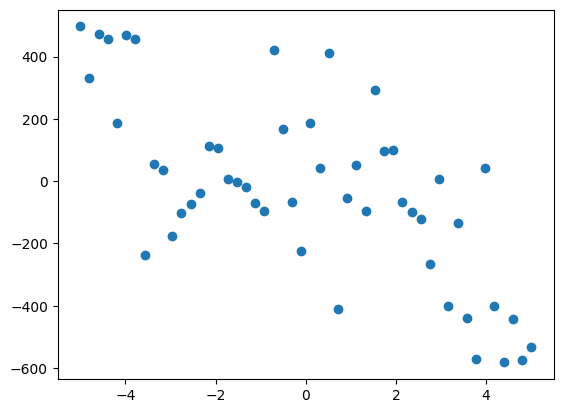

In [11]:
scatter(X, y)

### (b)

Trenirajte model polinomijalne regresije stupnja $d=3$. Na istom grafikonu prikažite naučeni model $h(\mathbf{x})=\mathbf{w}^\intercal\tilde{\mathbf{x}}$ i primjere za učenje. Izračunajte pogrešku učenja modela.

mse = 33277.668364606536


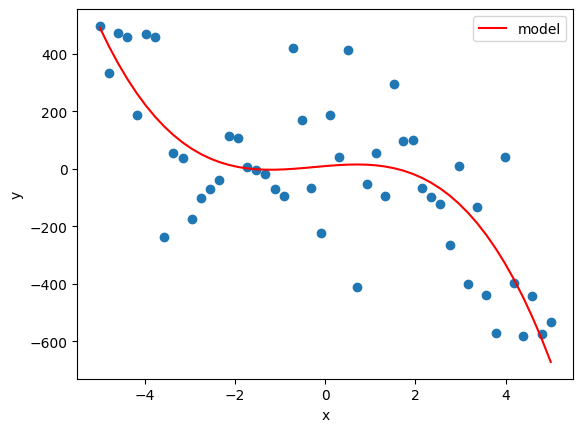

In [12]:
poly = PolynomialFeatures(degree=3)
matrix = poly.fit_transform(X)
model = LinearRegression()
model.fit(matrix, y)
y_pred = model.predict(matrix)
mse = mean_squared_error(y, y_pred)
print("mse =", mse)

scatter(X, y)
plot(X, y_pred, color='red', label='model')
xlabel('x')
ylabel('y')
legend()

### 3. Odabir modela

### (a)

Na skupu podataka iz zadatka 2 trenirajte pet modela linearne regresije $\mathcal{H}_d$ različite složenosti, gdje je $d$ stupanj polinoma, $d\in\{1,3,5,10,20\}$. Prikažite na istome grafikonu skup za učenje i funkcije $h_d(\mathbf{x})$ za svih pet modela (preporučujemo koristiti `plot` unutar `for` petlje). Izračunajte pogrešku učenja svakog od modela.

**Q:** Koji model ima najmanju pogrešku učenja i zašto?

mse 1 = 45001.68744401414
mse 3 = 33277.668364606536
mse 5 = 31453.665557331333
mse 10 = 28514.451595461625
mse 20 = 25658.735842696507


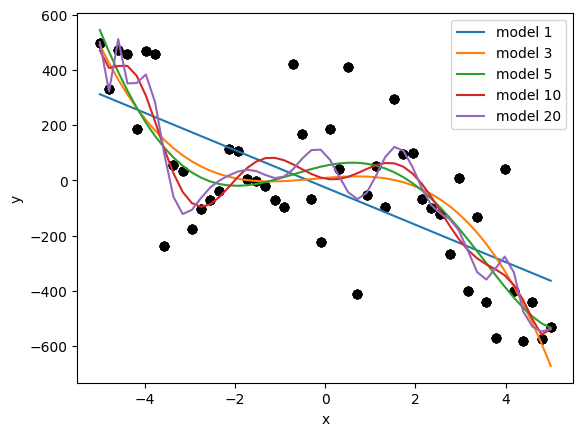

In [13]:
degrees = [1,3,5,10,20]
for d in degrees:
    poly = PolynomialFeatures(degree=d)
    matrix = poly.fit_transform(X)
    model = LinearRegression()
    model.fit(matrix, y)
    y_pred = model.predict(matrix)
    mse = mean_squared_error(y, y_pred)
    print("mse " + str(d) + " =", mse)

    scatter(X, y, color='black')
    label = 'model ' + str(d)
    plot(X, y_pred, label=label)
    xlabel('x')
    ylabel('y')
    legend()

### (b)

Razdvojite skup primjera iz zadatka 2 pomoću funkcije [`model_selection.train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) na skup za učenja i skup za ispitivanje u omjeru 1:1. Prikažite na jednom grafikonu pogrešku učenja i ispitnu pogrešku za modele polinomijalne regresije $\mathcal{H}_d$, sa stupnjem polinoma $d$ u rasponu $d\in [1,2,\ldots,20]$. Budući da kvadratna pogreška brzo raste za veće stupnjeve polinoma, umjesto da iscrtate izravno iznose pogrešaka, iscrtajte njihove logaritme.

**NB:** Podjela na skupa za učenje i skup za ispitivanje mora za svih dvadeset modela biti identična.

**Q:** Je li rezultat u skladu s očekivanjima? Koji biste model odabrali i zašto?

**Q:** Pokrenite iscrtavanje više puta. U čemu je problem? Bi li problem bio jednako izražen kad bismo imali više primjera? Zašto?

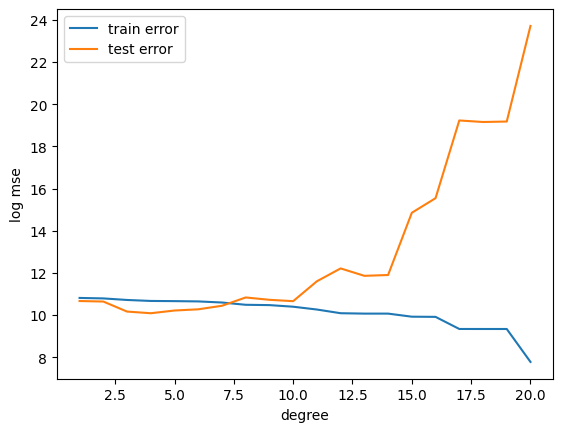

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5)

train_errors = []
test_errors = []
for d in range(1, 21):
    poly = PolynomialFeatures(degree=d)
    matrix_train = poly.fit_transform(X_train)
    matrix_test = poly.transform(X_test)
    model = LinearRegression()
    model.fit(matrix_train, y_train)
    y_pred_train = model.predict(matrix_train)
    y_pred_test = model.predict(matrix_test)
    train_errors.append(mean_squared_error(y_train, y_pred_train))
    test_errors.append(mean_squared_error(y_test, y_pred_test))

plot(range(1, 21), np.log(train_errors), label='train error')
plot(range(1, 21), np.log(test_errors), label='test error')
xlabel('degree')
ylabel('log mse')
legend()

### (c)

Točnost modela ovisi o (1) njegovoj složenosti (stupanj $d$ polinoma), (2) broju primjera $N$, i (3) količini šuma. Kako biste to analizirali, nacrtajte grafikone pogrešaka kao u 3b, ali za različit $N\in$ (trećina, dvije trećine, sve) i količine šuma $\sigma\in\{100,200,500\}$ (ukupno 9 grafikona). Upotrijebite funkciju [`subplots`](http://matplotlib.org/examples/pylab_examples/subplots_demo.html) kako biste pregledno posložili grafikone u tablicu $3\times 3$. Podatci se generiraju na isti način kao u zadatku 2.

**NB:** Pobrinite se da svi grafikoni budu generirani nad usporedivim skupovima podataka, na sljedeći način. Generirajte najprije svih 1000 primjera, podijelite ih na skupove za učenje i skupove za ispitivanje (dva skupa od po 500 primjera). Zatim i od skupa za učenje i od skupa za ispitivanje načinite tri različite verzije, svaka s drugačijom količinom šuma (ukupno 2x3=6 verzija podataka). Kako bi simulirali veličinu skupa podataka, od tih dobivenih 6 skupova podataka uzorkujte trećinu, dvije trećine i sve podatke. Time ste dobili 18 skupova podataka -- skup za učenje i za testiranje za svaki od devet grafova.

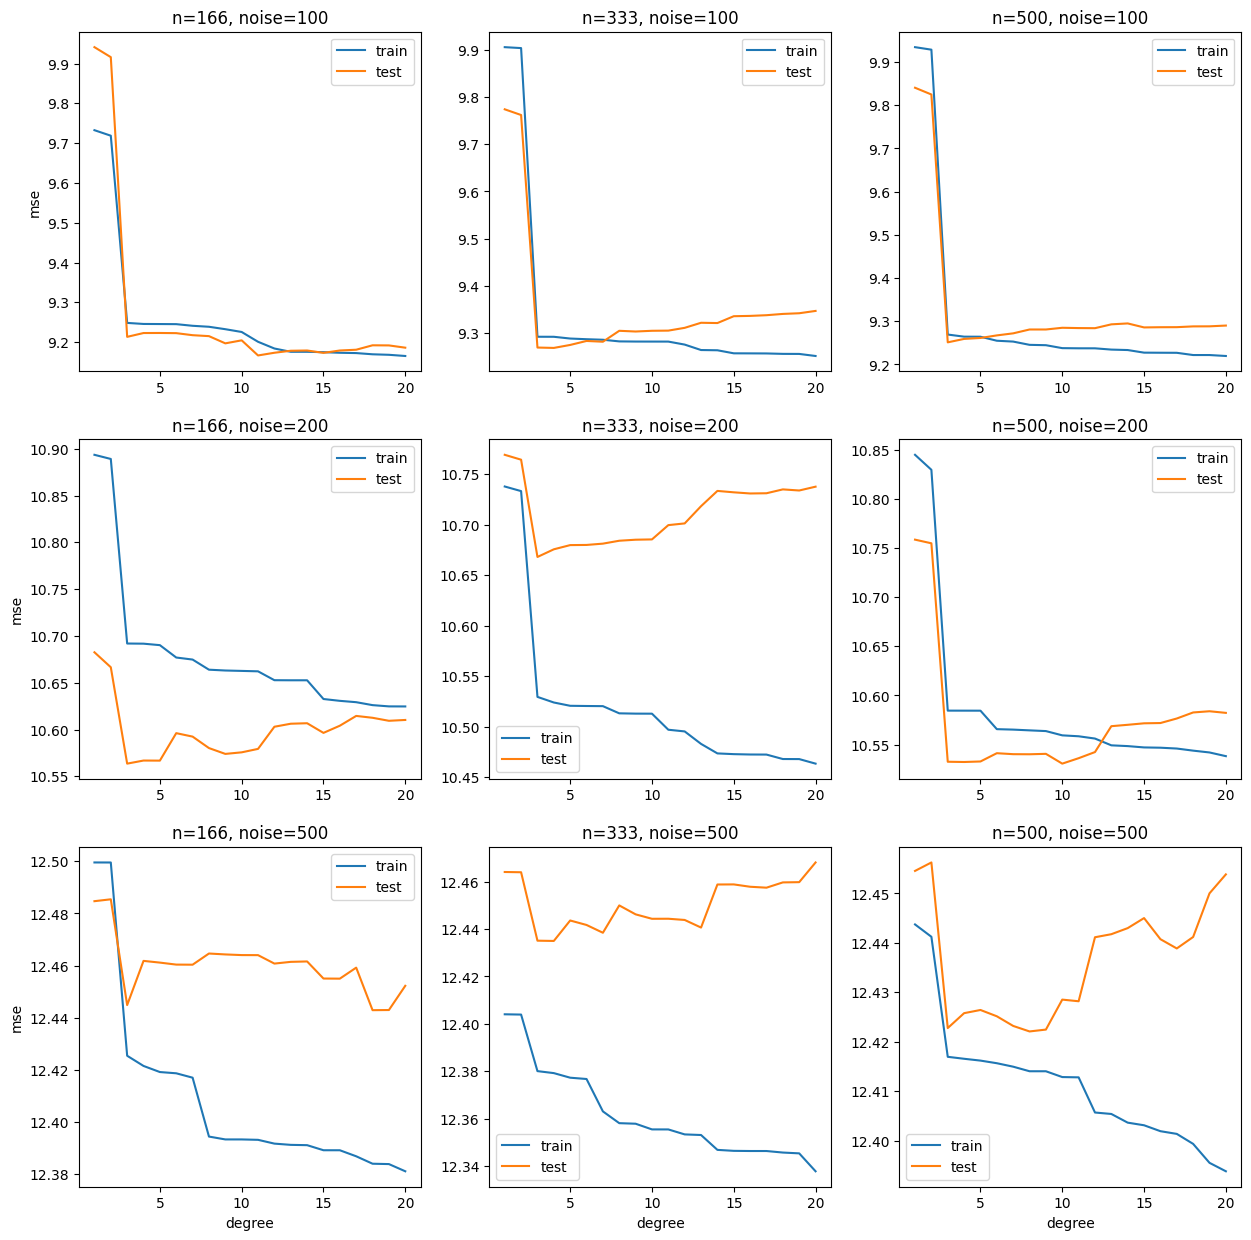

In [15]:
X = make_instances(-5, 5, 1000)
X_train, X_test = train_test_split(X, test_size=0.5)
ns = [500//3, 1000//3, 500]
noises = [100, 200, 500]

fig, axes = subplots(3, 3, figsize=(15, 15))

for i, noise in enumerate(noises):
    for j, n in enumerate(ns):
        y_train = make_labels(X_train[:n], f, noise=noise)
        y_test = make_labels(X_test[:n], f, noise=noise)

        train_errors = []
        test_errors = []
        for d in range(1, 21):
            poly = PolynomialFeatures(degree=d)
            matrix_train = poly.fit_transform(X_train[:n])
            matrix_test = poly.transform(X_test[:n])
            model = LinearRegression()
            model.fit(matrix_train, y_train)
            y_pred_train = model.predict(matrix_train)
            y_pred_test = model.predict(matrix_test)
            train_errors.append(mean_squared_error(y_train, y_pred_train))
            test_errors.append(mean_squared_error(y_test, y_pred_test))

        ax = axes[i, j]
        ax.plot(range(1, 21), np.log(train_errors), label='train')
        ax.plot(range(1, 21), np.log(test_errors), label='test')
        ax.set_title(f'n={n}, noise={noise}')
        if i == 2: ax.set_xlabel('degree')
        if j == 0: ax.set_ylabel('mse')
        ax.legend()

***Q:*** Jesu li rezultati očekivani? Obrazložite.

### 4. Regularizirana regresija

### (a)

U gornjim eksperimentima nismo koristili **regularizaciju**. Vratimo se najprije na primjer iz zadatka 1. Na primjerima iz tog zadatka izračunajte težine $\mathbf{w}$ za polinomijalni regresijski model stupnja $d=3$ uz L2-regularizaciju (tzv. *ridge regression*), prema izrazu $\mathbf{w}=(\mathbf{\Phi}^\intercal\mathbf{\Phi}+\lambda\mathbf{I})^{-1}\mathbf{\Phi}^\intercal\mathbf{y}$. Napravite izračun težina za regularizacijske faktore $\lambda=0$, $\lambda=1$ i $\lambda=10$ te usporedite dobivene težine.

**Q:** Kojih je dimenzija matrica koju treba invertirati?

**Q:** Po čemu se razlikuju dobivene težine i je li ta razlika očekivana? Obrazložite.

In [16]:
X = np.array([[0],[1],[2],[4]])
y = np.array([4,1,2,5])

poly = PolynomialFeatures(degree=3, include_bias=True)
matrix = poly.fit_transform(X)

lambdas = [0, 1, 10]

for l in lambdas:
    L = np.eye(matrix.shape[1]) * l
    L[0, 0] = 0

    weights = np.matmul(
            np.matmul(
                linalg.inv(
                    np.matmul(
                        np.transpose(matrix),
                        matrix
                    )
                   + L 
                ), 
                np.transpose(matrix)
            ),        y
    )

    print("l =", l, "\n weights =", weights)

l = 0 
 weights = [ 4.         -5.91666667  3.375      -0.45833333]
l = 1 
 weights = [ 3.05696145 -0.69079365 -0.2831746   0.1445805 ]
l = 10 
 weights = [ 2.49444184 -0.15897295 -0.13423067  0.0815601 ]


### (b)

Proučite klasu [`Ridge`](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html#sklearn.linear_model.Ridge) iz modula [`sklearn.linear_model`](http://scikit-learn.org/stable/modules/classes.html#module-sklearn.linear_model), koja implementira L2-regularizirani regresijski model. Parametar $\alpha$ odgovara parametru $\lambda$. Primijenite model na istim primjerima kao u prethodnom zadatku i ispišite težine $\mathbf{w}$ (atributi `coef_` i `intercept_`). Ponovno, pripazite na pomak.

**Q:** Jesu li težine identične onima iz zadatka 4a? Ako nisu, objasnite zašto je to tako i kako biste to popravili.

In [17]:
from sklearn.linear_model import Ridge
poly = PolynomialFeatures(degree=3, include_bias=False)
matrix = poly.fit_transform(X)

lambdas = [0, 1, 10]

for l in lambdas:
    model = Ridge(alpha=l, fit_intercept=True)
    model.fit(matrix, y)
    print("l =", l, "\n weights =", model.coef_)


l = 0 
 weights = [-5.91666667  3.375      -0.45833333]
l = 1 
 weights = [-0.69079365 -0.2831746   0.1445805 ]
l = 10 
 weights = [-0.15897295 -0.13423067  0.0815601 ]


### (c)

Vratimo se na slučaj $N=50$ slučajno generiranih primjera iz zadatka 2. Trenirajte modele polinomijalne regresije $\mathcal{H}_{\lambda,d}$ za $\lambda\in\{0,100\}$ i $d\in\{2,10\}$ (ukupno četiri modela). Skicirajte pripadne funkcije $h(\mathbf{x})$ i primjere (na jednom grafikonu; preporučujemo koristiti `plot` unutar `for` petlje).

**Q:** Jesu li rezultati očekivani? Obrazložite.

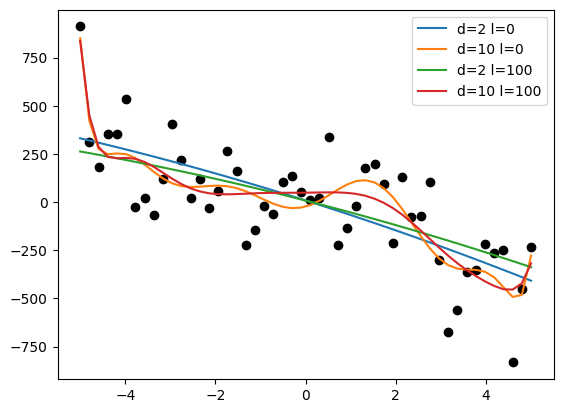

In [18]:
lambdas = [0, 100]
degrees = [2, 10]

X = make_instances(-5, 5, 50)
y = make_labels(X, f, noise=200)

for l in lambdas:
    for d in degrees:
        poly = PolynomialFeatures(degree=d, include_bias=False)
        matrix = poly.fit_transform(X)
        model = Ridge(alpha=l, fit_intercept=True)
        model.fit(matrix, y)
        y_pred = model.predict(matrix)
        label = "d=" + str(d) + " l=" + str(l)
        plot(X, y_pred, label=label)

scatter(X, y, color='black')
legend()


### (d)

Kao u zadataku 3b, razdvojite primjere na skup za učenje i skup za ispitivanje u omjeru 1:1. Prikažite krivulje logaritama pogreške učenja i ispitne pogreške u ovisnosti za model $\mathcal{H}_{d=10,\lambda}$, podešavajući faktor regularizacije $\lambda$ u rasponu $\lambda\in\{0,1,\dots,50\}$.

**Q:** Kojoj strani na grafikonu odgovara područje prenaučenosti, a kojoj podnaučenosti? Zašto?

**Q:** Koju biste vrijednosti za $\lambda$ izabrali na temelju ovih grafikona i zašto?


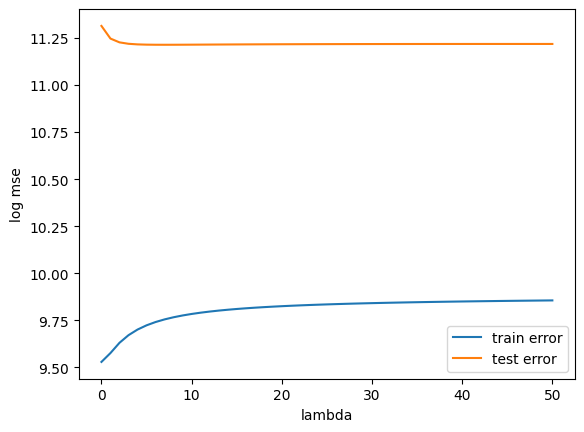

In [19]:
X = make_instances(-5, 5, 50)
y = make_labels(X, f, noise=200)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5)

lambdas = range(0, 51)
degree = 10
train_errors = []
test_errors = []

for l in lambdas:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    matrix_train = poly.fit_transform(X_train)
    matrix_test = poly.transform(X_test)
    model = Ridge(alpha=l, fit_intercept=True)
    model.fit(matrix_train, y_train)
    y_pred_train = model.predict(matrix_train)
    y_pred_test = model.predict(matrix_test)
    train_errors.append(mean_squared_error(y_train, y_pred_train))
    test_errors.append(mean_squared_error(y_test, y_pred_test))

plot(lambdas, np.log(train_errors), label='train error')
plot(lambdas, np.log(test_errors), label='test error')
xlabel('lambda')
ylabel('log mse')
legend()
        


### 5. L1-regularizacija i L2-regularizacija

Svrha regularizacije jest potiskivanje težina modela $\mathbf{w}$ prema nuli, kako bi model bio što jednostavniji. Složenost modela može se okarakterizirati normom pripadnog vektora težina $\mathbf{w}$, i to tipično L2-normom ili L1-normom. Za jednom trenirani model možemo izračunati i broj ne-nul značajki, ili L0-normu, pomoću sljedeće funkcije koja prima vektor težina $\mathbf{w}$:

In [20]:
def nonzeroes(coef, tol=1e-6): 
    return len(coef) - len(coef[np.isclose(0, coef, atol=tol)])

### (a)

Za ovaj zadatak upotrijebite skup za učenje i skup za testiranje iz zadatka 3b. Trenirajte modele **L2-regularizirane** polinomijalne regresije stupnja $d=5$, mijenjajući hiperparametar $\lambda$ u rasponu $\{1,2,\dots,100\}$. Za svaki od treniranih modela izračunajte L{0,1,2}-norme vektora težina $\mathbf{w}$ te ih prikažite kao funkciju od $\lambda$. Pripazite što točno šaljete u funkciju za izračun normi.

**Q:** Objasnite oblik obiju krivulja. Hoće li krivulja za $\|\mathbf{w}\|_2$ doseći nulu? Zašto? Je li to problem? Zašto?

**Q:** Za $\lambda=100$, koliki je postotak težina modela jednak nuli, odnosno koliko je model rijedak?

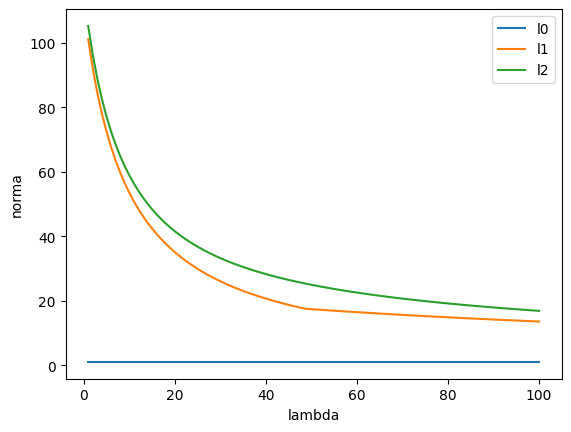

In [21]:
from sklearn.linear_model import Ridge
lambdas = range(1, 101)
X = make_instances(-5, 5, 50)
y = make_labels(X, f, noise=200)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5)

l0s = []
l1s = []
l2s = []

for l in lambdas:
    poly = PolynomialFeatures(degree=5, include_bias=False)
    matrix_train = poly.fit_transform(X_train)
    matrix_test = poly.transform(X_test)
    model = Ridge(alpha=l, fit_intercept=True)
    model.fit(matrix_train, y_train)

    l0s.append(nonzeroes(model.coef_))
    l1s.append(linalg.norm(model.coef_, ord=1))
    l2s.append(linalg.norm(model.coef_, ord=2))

plot(lambdas, l0s, label="l0")
plot(lambdas, l1s, label="l1")
plot(lambdas, l2s, label="l2")
xlabel('lambda')
ylabel('norma')
legend()

### (b)

Glavna prednost L1-regularizirane regresije (ili *LASSO regression*) nad L2-regulariziranom regresijom jest u tome što L1-regularizirana regresija rezultira **rijetkim modelima** (engl. *sparse models*), odnosno modelima kod kojih su mnoge težine pritegnute na nulu. Pokažite da je to doista tako, ponovivši gornji eksperiment s **L1-regulariziranom** regresijom, implementiranom u klasi  [`Lasso`](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) u modulu [`sklearn.linear_model`](http://scikit-learn.org/stable/modules/classes.html#module-sklearn.linear_model).

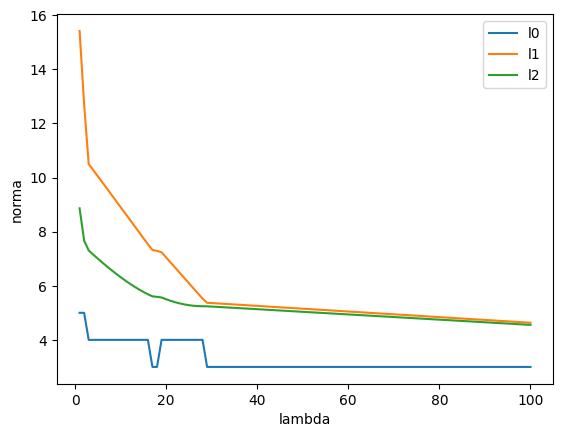

In [22]:
from sklearn.linear_model import Lasso
lambdas = range(1, 101)
X = make_instances(-5, 5, 50)
y = make_labels(X, f, noise=200)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5)

l0s = []
l1s = []
l2s = []

for l in lambdas:
    poly = PolynomialFeatures(degree=5, include_bias=False)
    matrix_train = poly.fit_transform(X_train)
    matrix_test = poly.transform(X_test)
    # nekad dobijem warning bez max_iter
    model = Lasso(alpha=l, fit_intercept=True, max_iter=2000)
    model.fit(matrix_train, y_train)

    l0s.append(nonzeroes(model.coef_))
    l1s.append(linalg.norm(model.coef_, ord=1))
    l2s.append(linalg.norm(model.coef_, ord=2))

plot(lambdas, l0s, label="l0")
plot(lambdas, l1s, label="l1")
plot(lambdas, l2s, label="l2")
xlabel('lambda')
ylabel('norma')
legend()

### 6. Značajke različitih skala

Često se u praksi možemo susreti sa podatcima u kojima sve značajke nisu jednakih magnituda. Primjer jednog takvog skupa je regresijski skup podataka `grades` u kojem se predviđa prosjek ocjena studenta na studiju (1--5) na temelju dvije značajke: bodova na prijamnom ispitu (1--3000) i prosjeka ocjena u srednjoj školi. Prosjek ocjena na studiju izračunat je kao težinska suma ove dvije značajke uz dodani šum.

Koristite sljedeći kôd kako biste generirali ovaj skup podataka.

In [23]:
n_data_points = 500
np.random.seed(69)

# Generiraj podatke o bodovima na prijamnom ispitu koristeći normalnu razdiobu i ograniči ih na interval [1, 3000].
exam_score = np.random.normal(loc=1500.0, scale = 500.0, size = n_data_points) 
exam_score = np.round(exam_score)
exam_score[exam_score > 3000] = 3000
exam_score[exam_score < 0] = 0

# Generiraj podatke o ocjenama iz srednje škole koristeći normalnu razdiobu i ograniči ih na interval [1, 5].
grade_in_highschool = np.random.normal(loc=3, scale = 2.0, size = n_data_points)
grade_in_highschool[grade_in_highschool > 5] = 5
grade_in_highschool[grade_in_highschool < 1] = 1

# Matrica dizajna.
grades_X = np.array([exam_score,grade_in_highschool]).T

# Završno, generiraj izlazne vrijednosti.
rand_noise = np.random.normal(loc=0.0, scale = 0.5, size = n_data_points)
exam_influence = 0.9
grades_y = ((exam_score / 3000.0) * (exam_influence) + (grade_in_highschool / 5.0) \
            * (1.0 - exam_influence)) * 5.0 + rand_noise
grades_y[grades_y < 1] = 1
grades_y[grades_y > 5] = 5

### a)

Iscrtajte ovisnost ciljne vrijednosti (y-os) o prvoj i o drugoj značajki (x-os). Iscrtajte dva odvojena grafa.

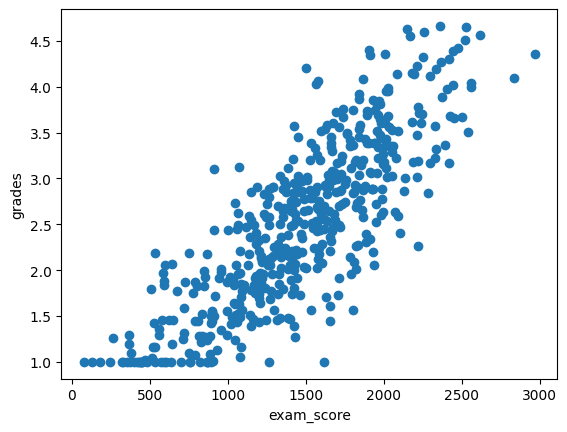

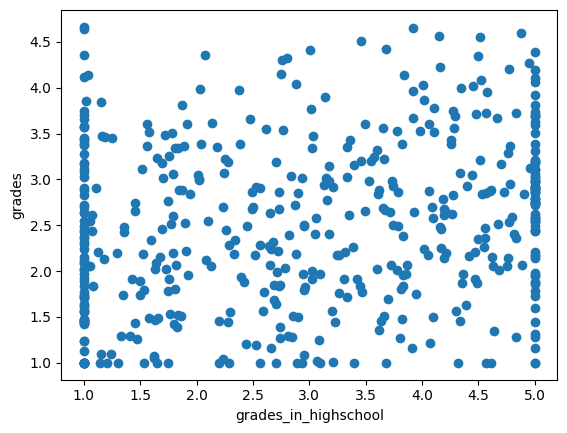

In [24]:
scatter(exam_score, grades_y)
xlabel("exam_score")
ylabel("grades")
show()
scatter(grade_in_highschool, grades_y)
xlabel("grades_in_highschool")
ylabel("grades")
show()

### b)

Naučite model L2-regularizirane regresije ($\lambda = 0.01$), na podacima `grades_X` i `grades_y`:

In [25]:
model = Ridge(alpha=0.01)
model.fit(grades_X, grades_y)
print(model.coef_)

[0.00141497 0.09477276]


Sada ponovite gornji eksperiment, ali prvo skalirajte podatke `grades_X` i `grades_y` i spremite ih u varijable `grades_X_fixed` i `grades_y_fixed`. Za tu svrhu, koristite [`StandardScaler`](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

In [26]:
from sklearn.preprocessing import StandardScaler
scaler_X = StandardScaler()
grades_X_fixed = scaler_X.fit_transform(grades_X)
scaler_y = StandardScaler()
grades_y_fixed = scaler_y.fit_transform(grades_y.reshape(-1, 1)).flatten()
model = Ridge(alpha=0.01)
model.fit(grades_X_fixed, grades_y_fixed)
print(model.coef_)

[0.81630375 0.15167761]


**Q:** Gledajući grafikone iz podzadatka (a), koja značajka bi trebala imati veću magnitudu, odnosno važnost pri predikciji prosjeka na studiju? Odgovaraju li težine Vašoj intuiciji? Objasnite.  

### 7. Multikolinearnost

### a)

Izradite skup podataka `grades_X_fixed_colinear` tako što ćete u skupu `grades_X_fixed` iz
zadatka *7b* duplicirati zadnji stupac (ocjenu iz srednje škole). Time smo efektivno uveli savršenu multikolinearnost.

In [27]:
grades_X_fixed_colinear = np.hstack([grades_X_fixed, grades_X_fixed[:, -1:]])

Ponovno, naučite na ovom skupu L2-regularizirani model regresije ($\lambda = 0.01$).

In [28]:
model = Ridge(alpha=0.01)
model.fit(grades_X_fixed_colinear, grades_y_fixed)
print(model.coef_)

[0.81630364 0.07583957 0.07583957]


**Q:** Usporedite iznose težina s onima koje ste dobili u zadatku *7b*. Što se dogodilo?

### b)

Slučajno uzorkujte 50% elemenata iz skupa `grades_X_fixed_colinear` i naučite dva modela L2-regularizirane regresije, jedan s $\lambda=0.01$ i jedan s $\lambda=1000$). Ponovite ovaj pokus 10 puta (svaki put s drugim podskupom od 50% elemenata).  Za svaki model, ispišite dobiveni vektor težina u svih 10 ponavljanja te ispišite standardnu devijaciju vrijednosti svake od težina (ukupno šest standardnih devijacija, svaka dobivena nad 10 vrijednosti).

In [30]:
lambdas = [0.01, 1000]

model1 = Ridge(alpha=0.01)
model2 = Ridge(alpha=1000)
weights1 = []
weights2 = []

for i in range(10):
    X_sample1, X_sample2, y_sample1, y_sample2 = train_test_split(grades_X_fixed_colinear, grades_y, test_size=0.5, random_state=i)

    model1.fit(X_sample1, y_sample1)
    model2.fit(X_sample2, y_sample2)

    weights1.append(model1.coef_)
    weights2.append(model2.coef_)

weights1 = np.array(weights1)
weights2 = np.array(weights2)
print("weights 0.01 = ")
print(weights1)
std1 = np.std(weights1, axis=0)

print("std 0.01 = ", std1)
print("weights 1000 = ")
print(weights2)
std2 = np.std(weights2, axis=0)
print("std 1000 = ", std2)

weights 0.01 = 
[[0.74310419 0.04471543 0.04471543]
 [0.7447013  0.07529311 0.07529311]
 [0.75896844 0.0599973  0.0599973 ]
 [0.73475739 0.05688592 0.05688592]
 [0.72921771 0.08491027 0.08491027]
 [0.74412885 0.07192784 0.07192784]
 [0.74671573 0.07025163 0.07025163]
 [0.73686251 0.07338763 0.07338763]
 [0.73732839 0.06496878 0.06496878]
 [0.71621604 0.07848136 0.07848136]]
std 0.01 =  [0.0108337 0.0111238 0.0111238]
weights 1000 = 
[[0.14938727 0.04219118 0.04219118]
 [0.15013553 0.02688336 0.02688336]
 [0.14439823 0.03729463 0.03729463]
 [0.14815656 0.02942597 0.02942597]
 [0.16079956 0.02647073 0.02647073]
 [0.15630825 0.02680823 0.02680823]
 [0.14648694 0.02681514 0.02681514]
 [0.14663607 0.02712485 0.02712485]
 [0.13962726 0.02646466 0.02646466]
 [0.15173454 0.0270973  0.0270973 ]]
std 1000 =  [0.00567318 0.00522192 0.00522192]


**Q:** Kako regularizacija utječe na stabilnost težina?  
**Q:** Jesu li koeficijenti jednakih magnituda kao u prethodnom pokusu? Objasnite zašto.